# 04 — Model Evaluation, Interpretation and Recommendations

## Project
OSMI 2016 Mental Health in Technology-related Jobs

## Objective
Evaluate the clustering solutions developed in Notebook 03 and determine whether the selected solution provides a defensible and interpretable segmentation of workplace mental-health climate.

This notebook evaluates:

1. Internal cluster separation.
2. Cluster size distribution and coverage.
3. Model-specific diagnostics produced during modelling.
4. Cluster response profiles across the three workplace-climate domains.
5. Supplementary associations with excluded contextual variables.
6. Practical interpretability and organisational relevance.
7. Limitations and recommendations.

## Methodological boundaries

- The 1,131-person eligible cohort and 15 primary features remain unchanged.
- The three feature domains remain unchanged.
- No clustering algorithm is refitted.
- No new feature encoding, imputation or feature selection is performed.
- Demographic and contextual variables are not used to construct clusters.
- Model-specific metrics are interpreted within their appropriate methodological context.
- The final recommendation is based on multiple lines of evidence, not one metric.

## Expected outcome

A documented recommendation on whether the selected clustering solution is suitable for exploratory workplace-climate segmentation, together with cluster profiles, organisational implications and limitations.

In [21]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency, kruskal
from sklearn.metrics import silhouette_score

from statsmodels.stats.multitest import multipletests


RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 150)
pd.set_option("display.width", 160)

sns.set_theme(
    style="whitegrid",
    context="notebook",
)

warnings.filterwarnings(
    "ignore",
    category=FutureWarning,
)

# PROJECT PATHS

PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data"

PROCESSED_DIR = DATA_DIR / "processed"

REPORTS_DIR = PROJECT_ROOT / "reports"

MODELLING_DIR = REPORTS_DIR / "results" / "data_modelling"

EVALUATION_DIR = REPORTS_DIR / "evaluation"

FIGURES_DIR = REPORTS_DIR / "figures" / "model_evaluation"

TABLES_DIR = EVALUATION_DIR / "tables"

for directory in [
    EVALUATION_DIR,
    FIGURES_DIR,
    TABLES_DIR,
]:
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )

# NOTEBOOK 02 INPUTS

PRIMARY_COHORT_FILE = (
    PROCESSED_DIR
    / "osmi_2016_primary_cohort.csv"
)

ROW_MAPPING_FILE = (
    PROCESSED_DIR
    / "osmi_2016_model_row_mapping.csv"
)

FEATURE_METADATA_FILE = (
    PROCESSED_DIR
    / "osmi_2016_feature_metadata.csv"
)

GOWER_MATRIX_FILE = (
    PROCESSED_DIR
    / "osmi_2016_gower_dissimilarity.npy"
)


# NOTEBOOK 03 OUTPUTS

# These filenames must correspond to the final export
# section of Notebook 03.
#
# The expected candidate-label format is either:
#
# LONG:
# model_key | model_row_index | cluster_label
#
# WIDE:
# model_row_index | kmodes_k... | mca_kmeans_k... | ...
#
# Candidate metrics should contain a model_key column.

CANDIDATE_LABELS_FILE = (
    MODELLING_DIR
    / "osmi_2016_candidate_cluster_labels.csv"
)

CANDIDATE_METRICS_FILE = (
    MODELLING_DIR
    / "osmi_2016_model_comparison.csv"
)

SELECTED_MODEL_FILE = (
    MODELLING_DIR
    / "osmi_2016_selected_model.json"
)

# Set this to the exact model key selected in Notebook 03.
#
# Example only:
# SELECTED_MODEL_KEY = "kmodes_k4"
#
# Do not use the example unless that is the actual selection.

SELECTED_MODEL_KEY = "HDBSCAN"


print("Project root:", PROJECT_ROOT)
print("Processed data:", PROCESSED_DIR)
print("Modelling outputs:", MODELLING_DIR)
print("Evaluation outputs:", EVALUATION_DIR)

Project root: c:\Users\User\Documents\Projects\osmi-mental-health-data-clustering
Processed data: c:\Users\User\Documents\Projects\osmi-mental-health-data-clustering\data\processed
Modelling outputs: c:\Users\User\Documents\Projects\osmi-mental-health-data-clustering\reports\results\data_modelling
Evaluation outputs: c:\Users\User\Documents\Projects\osmi-mental-health-data-clustering\reports\evaluation


## 1. Evaluation scope and feature definitions

The clustering analysis represents three dimensions of workplace
mental-health climate.

### Employer support

Organisational benefits, formal discussion, available resources,
anonymity protections, medical leave and perceived seriousness
of mental health relative to physical health.

### Psychological safety

Perceived consequences of discussing mental health and physical
health, comfort discussing mental health with colleagues and
supervisors, and observed consequences for employees.

### Disclosure and career climate

Perceived career consequences of disclosure, willingness to disclose
during interviews and anticipated negative perceptions from colleagues.

These are the only dimensions used to construct the primary clusters.

The evaluation uses the same definitions as Notebook 01 and Notebook 02.

In [22]:
FEATURES_BY_DOMAIN = {
    "employer_support": [
        "mh_benefits",
        "mh_formal_discussion",
        "mh_resources_offered",
        "mh_anonymity_protected",
        "mh_medical_leave_ease",
        "mh_vs_ph_seriousness",
    ],

    "psychological_safety": [
        "mh_discussion_consequences",
        "ph_discussion_consequences",
        "mh_comfort_coworkers",
        "mh_comfort_supervisor",
        "observed_mh_consequences",
    ],

    "disclosure_career_climate": [
        "interview_ph_reveal",
        "interview_mh_reveal",
        "mh_hurt_career",
        "coworker_negative_view",
    ],
}

PRIMARY_FEATURES = [
    feature
    for features in FEATURES_BY_DOMAIN.values()
    for feature in features
]

EXPECTED_COHORT_SIZE = 1131

EXPECTED_FEATURE_COUNT = 15

assert len(PRIMARY_FEATURES) == EXPECTED_FEATURE_COUNT

assert len(set(PRIMARY_FEATURES)) == EXPECTED_FEATURE_COUNT

print("Primary features:", len(PRIMARY_FEATURES))

for domain, features in FEATURES_BY_DOMAIN.items():
    print(f"{domain}: {len(features)} features")

Primary features: 15
employer_support: 6 features
psychological_safety: 5 features
disclosure_career_climate: 4 features


## 2. Load the prepared data and modelling outputs

The primary cohort, row mapping, feature metadata and Gower matrix
are imported from Notebook 02.

Candidate cluster labels and model diagnostics are imported from
Notebook 03.

The selected model is identified using the selection recorded in
Notebook 03.

No input is reprocessed or transformed in this stage.

In [23]:
required_files = {
    "primary_cohort": PRIMARY_COHORT_FILE,
    "row_mapping": ROW_MAPPING_FILE,
    "feature_metadata": FEATURE_METADATA_FILE,
    "gower_matrix": GOWER_MATRIX_FILE,
    "candidate_labels": CANDIDATE_LABELS_FILE,
}

missing_files = [
    name
    for name, path in required_files.items()
    if not path.exists()
]

if missing_files:
    raise FileNotFoundError(
        "Required evaluation inputs are missing:\n"
        + "\n".join(
            f"- {name}: {required_files[name]}"
            for name in missing_files
        )
    )

if not CANDIDATE_METRICS_FILE.exists():
    raise FileNotFoundError(
        f"Candidate metrics file not found: "
        f"{CANDIDATE_METRICS_FILE}"
    )


cohort = pd.read_csv(
    PRIMARY_COHORT_FILE,
)

row_mapping = pd.read_csv(
    ROW_MAPPING_FILE,
)

feature_metadata = pd.read_csv(
    FEATURE_METADATA_FILE,
)

D_gower = np.load(
    GOWER_MATRIX_FILE,
    allow_pickle=False,
)

candidate_labels_raw = pd.read_csv(
    CANDIDATE_LABELS_FILE,
)

candidate_metrics = pd.read_csv(
    CANDIDATE_METRICS_FILE,
)


print("Cohort shape:", cohort.shape)
print("Row mapping shape:", row_mapping.shape)
print("Feature metadata shape:", feature_metadata.shape)
print("Gower matrix shape:", D_gower.shape)
print("Candidate labels shape:", candidate_labels_raw.shape)
print("Candidate metrics shape:", candidate_metrics.shape)

Cohort shape: (1131, 65)
Row mapping shape: (1131, 2)
Feature metadata shape: (15, 7)
Gower matrix shape: (1131, 1131)
Candidate labels shape: (1131, 41)
Candidate metrics shape: (39, 10)


In [24]:
if SELECTED_MODEL_FILE.exists():

    with open(
        SELECTED_MODEL_FILE,
        "r",
        encoding="utf-8",
    ) as file:

        selected_model_metadata = json.load(file)

    if SELECTED_MODEL_KEY is None:

        SELECTED_MODEL_KEY = (
            selected_model_metadata.get("selected_model_key")
        )

else:

    selected_model_metadata = {}


if SELECTED_MODEL_KEY is None:

    raise ValueError(
        "No selected model has been specified.\n\n"
        "Set SELECTED_MODEL_KEY in Cell 2 to the exact "
        "model key selected in Notebook 03, or provide "
        "the selected-model JSON export."
    )


print("Selected model:", SELECTED_MODEL_KEY)

Selected model: HDBSCAN


## 3. Data and row-alignment validation

Before calculating evaluation metrics, the notebook verifies:

- The eligible cohort contains 1,131 respondents.
- The primary clustering feature set contains 15 features.
- All 15 features are present in the cohort.
- The row mapping contains 1,131 unique model-row indices.
- Model-row indices are in the expected order.
- The Gower matrix is square, symmetric and finite.
- The Gower matrix has a zero diagonal.
- Candidate labels cover the expected respondent rows.

These checks prevent evaluation results from being associated
with the wrong respondents.

In [25]:
assert len(cohort) == EXPECTED_COHORT_SIZE

assert len(row_mapping) == EXPECTED_COHORT_SIZE

assert len(PRIMARY_FEATURES) == EXPECTED_FEATURE_COUNT

assert D_gower.shape == (
    EXPECTED_COHORT_SIZE,
    EXPECTED_COHORT_SIZE,
)

missing_features = [
    feature
    for feature in PRIMARY_FEATURES
    if feature not in cohort.columns
]

assert not missing_features, (
    f"Missing primary features: {missing_features}"
)

assert "model_row_index" in row_mapping.columns

assert "source_row_position" in row_mapping.columns

assert row_mapping["model_row_index"].is_unique

assert row_mapping["source_row_position"].is_unique

assert np.array_equal(
    row_mapping["model_row_index"].to_numpy(),
    np.arange(EXPECTED_COHORT_SIZE),
)

assert np.isfinite(D_gower).all()

assert np.allclose(
    D_gower,
    D_gower.T,
    atol=1e-7,
)

assert np.allclose(
    np.diag(D_gower),
    0,
    atol=1e-7,
)

assert D_gower.min() >= -1e-7

assert D_gower.max() <= 1 + 1e-7

assert not cohort[PRIMARY_FEATURES].isna().any().any()


print("All primary data validation checks passed.")

All primary data validation checks passed.


## 4. Standardise candidate cluster labels

Candidate labels may be exported in either long or wide format.

The evaluation notebook converts them into a standard wide structure:

- One row per model respondent.
- One column per candidate solution.
- One integer cluster label per respondent.
- Negative labels are retained as noise labels where applicable.

For HDBSCAN, the conventional noise label is -1.

The model key is retained so that the selected solution can be
identified unambiguously.

In [26]:
labels_df = candidate_labels_raw.copy()

if "model_key" in labels_df.columns:

    # Long format
    if "cluster_label" not in labels_df.columns:
        if "cluster" in labels_df.columns:
            labels_df = labels_df.rename(
                columns={"cluster": "cluster_label"}
            )
        else:
            raise ValueError(
                "Long-format labels must contain "
                "'cluster_label' or 'cluster'."
            )

    assert "model_row_index" in labels_df.columns

    labels_df["model_row_index"] = (
        labels_df["model_row_index"].astype(int)
    )

    labels_wide = labels_df.pivot(
        index="model_row_index",
        columns="model_key",
        values="cluster_label",
    )

    labels_wide.columns.name = None

    labels_wide = labels_wide.reset_index()

else:

    # Wide format
    if "model_row_index" not in labels_df.columns:
        raise ValueError(
            "Wide-format candidate labels must contain "
            "'model_row_index'."
        )

    labels_wide = labels_df.copy()


labels_wide["model_row_index"] = (
    labels_wide["model_row_index"].astype(int)
)

labels_wide = labels_wide.sort_values(
    "model_row_index"
).reset_index(drop=True)


assert len(labels_wide) == EXPECTED_COHORT_SIZE

assert labels_wide["model_row_index"].is_unique

assert np.array_equal(
    labels_wide["model_row_index"].to_numpy(),
    np.arange(EXPECTED_COHORT_SIZE),
)


candidate_model_keys = [
    column
    for column in labels_wide.columns
    if column != "model_row_index"
]

assert candidate_model_keys, (
    "No candidate model-label columns were found."
)

assert SELECTED_MODEL_KEY in candidate_model_keys, (
    f"Selected model '{SELECTED_MODEL_KEY}' "
    "was not found in the candidate labels."
)


for model_key in candidate_model_keys:

    assert labels_wide[model_key].notna().all(), (
        f"Missing labels found for {model_key}."
    )

    labels_wide[model_key] = (
        labels_wide[model_key].astype(int)
    )


print("Candidate solutions:", len(candidate_model_keys))

display(
    labels_wide.head()
)

AssertionError: Selected model 'HDBSCAN' was not found in the candidate labels.

In [27]:
selected_labels = (
    labels_wide[SELECTED_MODEL_KEY]
    .to_numpy(dtype=int)
)

assert len(selected_labels) == EXPECTED_COHORT_SIZE

selected_cluster_labels = sorted(
    label
    for label in np.unique(selected_labels)
    if label != -1
)

selected_cluster_count = len(
    selected_cluster_labels
)

selected_noise_count = int(
    np.sum(selected_labels == -1)
)

selected_noise_share = (
    selected_noise_count / EXPECTED_COHORT_SIZE
)

selected_coverage = (
    1 - selected_noise_share
)


print("Selected model:", SELECTED_MODEL_KEY)
print("Number of assigned clusters:", selected_cluster_count)
print("Noise observations:", selected_noise_count)
print("Noise share:", f"{selected_noise_share:.2%}")
print("Assigned coverage:", f"{selected_coverage:.2%}")


if selected_cluster_count < 2:

    raise ValueError(
        "The selected solution has fewer than two assigned clusters. "
        "Cluster-level separation and profiling cannot be evaluated."
    )

KeyError: 'HDBSCAN'

## 5. Candidate cluster-size evaluation

A clustering solution may produce apparently strong separation
while creating clusters that are too small to support meaningful
interpretation.

This section calculates:

- Number of assigned clusters.
- Number of respondents assigned to clusters.
- Number of noise observations.
- Noise percentage.
- Smallest cluster size.
- Largest cluster size.
- Cluster-size imbalance.

For HDBSCAN, noise observations are excluded from the assigned
cluster count and are reported separately.

A small cluster is not automatically invalid. It requires
substantive examination and should not be removed simply because
it is small.

In [28]:
candidate_size_results = []

candidate_cluster_sizes = {}

for model_key in candidate_model_keys:

    labels = labels_wide[model_key].to_numpy(dtype=int)

    assigned_labels = labels[labels != -1]

    unique_clusters, counts = np.unique(
        assigned_labels,
        return_counts=True,
    )

    cluster_sizes = dict(
        zip(unique_clusters, counts)
    )

    candidate_cluster_sizes[model_key] = cluster_sizes

    noise_count = int(
        np.sum(labels == -1)
    )

    noise_share = (
        noise_count / len(labels)
    )

    if len(counts) > 0:

        smallest_cluster = int(
            counts.min()
        )

        largest_cluster = int(
            counts.max()
        )

        size_ratio = (
            largest_cluster / smallest_cluster
        )

    else:

        smallest_cluster = 0
        largest_cluster = 0
        size_ratio = np.nan


    candidate_size_results.append({
        "model_key": model_key,
        "cluster_count": len(unique_clusters),
        "assigned_respondents": len(assigned_labels),
        "noise_count": noise_count,
        "noise_share": noise_share,
        "coverage": 1 - noise_share,
        "smallest_cluster": smallest_cluster,
        "largest_cluster": largest_cluster,
        "largest_to_smallest_ratio": size_ratio,
    })


candidate_size_summary = pd.DataFrame(
    candidate_size_results
).sort_values(
    "model_key"
).reset_index(drop=True)


display(
    candidate_size_summary.style.format({
        "noise_share": "{:.2%}",
        "coverage": "{:.2%}",
        "largest_to_smallest_ratio": "{:.2f}",
    })
)

,model_key,cluster_count,assigned_respondents,noise_count,noise_share,coverage,smallest_cluster,largest_cluster,largest_to_smallest_ratio
0,agglomerative_k10,10,1131,0,0.00%,100.00%,2,665,332.50
1,agglomerative_k2,2,1131,0,0.00%,100.00%,2,1129,564.50
2,agglomerative_k3,3,1131,0,0.00%,100.00%,2,1121,560.50
3,agglomerative_k4,4,1131,0,0.00%,100.00%,2,678,339.00
4,agglomerative_k5,5,1131,0,0.00%,100.00%,2,678,339.00
5,agglomerative_k6,6,1131,0,0.00%,100.00%,2,671,335.50
6,agglomerative_k7,7,1131,0,0.00%,100.00%,2,665,332.50
7,agglomerative_k8,8,1131,0,0.00%,100.00%,2,665,332.50
8,agglomerative_k9,9,1131,0,0.00%,100.00%,2,665,332.50
9,hdbscan_mcs15_ms10,3,128,1003,88.68%,11.32%,29,60,2.07


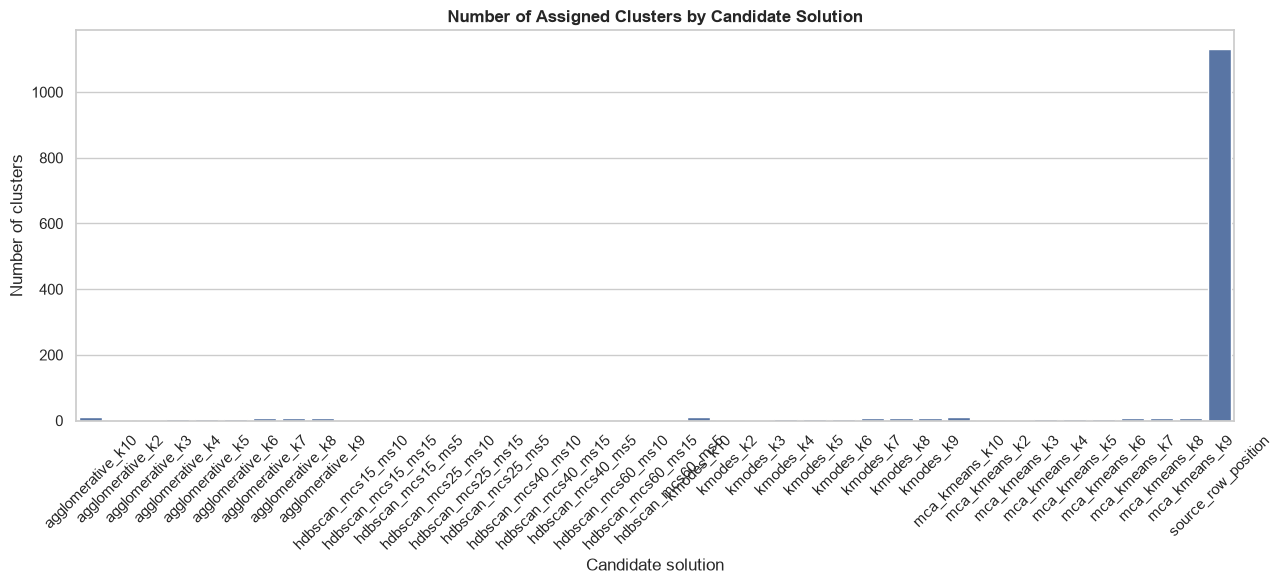

In [29]:
fig, ax = plt.subplots(
    figsize=(13, 6),
)

sns.barplot(
    data=candidate_size_summary,
    x="model_key",
    y="cluster_count",
    ax=ax,
)

ax.set_title(
    "Number of Assigned Clusters by Candidate Solution",
    weight="bold",
)

ax.set_xlabel("Candidate solution")

ax.set_ylabel("Number of clusters")

ax.tick_params(
    axis="x",
    rotation=45,
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "candidate_cluster_counts.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## 6. Common-representation separation diagnostic

The Gower dissimilarity matrix provides a common distance-based diagnostic for the candidate cluster assignments.

For each candidate solution, the silhouette coefficient is calculated using the same precomputed Gower matrix.

The silhouette coefficient is:

$$
s(i)=\frac{b(i)-a(i)}{\max(a(i),b(i))}
$$

where:

- $(a(i))$ is the mean dissimilarity between observation $(i)$ and the other observations in its assigned cluster.
- $(b(i))$ is the lowest mean dissimilarity between observation $(i)$ and another cluster.

The score ranges from -1 to +1.

Interpretation:

- Values closer to +1 indicate stronger separation.
- Values near 0 indicate overlapping or weakly separated clusters.
- Negative values indicate that observations may be closer to another cluster than to their assigned cluster.

### Important methodological qualification

The models optimise different representations:

- K-Modes optimises categorical mismatch cost.
- MCA + K-Means optimises Euclidean distances in MCA coordinates.
- Agglomerative clustering uses Gower dissimilarity.
- HDBSCAN uses Gower dissimilarity and identifies noise.

Consequently, the common Gower silhouette is a supplementary cross-model diagnostic, not a universal ranking metric.

For HDBSCAN, noise observations are excluded from the silhouette calculation. Its score must therefore be interpreted alongside coverage and noise share.

In [30]:
def calculate_gower_silhouette(
    distance_matrix,
    labels,
):
    labels = np.asarray(labels)

    assigned_mask = labels != -1

    assigned_indices = np.flatnonzero(
        assigned_mask
    )

    assigned_labels = labels[
        assigned_mask
    ]

    unique_labels = np.unique(
        assigned_labels
    )

    if len(unique_labels) < 2:
        return np.nan

    if len(assigned_labels) <= len(unique_labels):
        return np.nan

    D_subset = distance_matrix[
        np.ix_(
            assigned_indices,
            assigned_indices,
        )
    ]

    if not np.isfinite(D_subset).all():
        return np.nan

    return silhouette_score(
        D_subset,
        assigned_labels,
        metric="precomputed",
    )


common_silhouette_results = []

for model_key in candidate_model_keys:

    labels = labels_wide[
        model_key
    ].to_numpy(dtype=int)

    score = calculate_gower_silhouette(
        D_gower,
        labels,
    )

    common_silhouette_results.append({
        "model_key": model_key,
        "gower_silhouette": score,
    })


common_silhouette_summary = pd.DataFrame(
    common_silhouette_results
)


display(
    common_silhouette_summary.style.format({
        "gower_silhouette": "{:.4f}",
    })
)

,model_key,gower_silhouette
0,source_row_position,nan
1,kmodes_k2,0.1842
2,kmodes_k3,0.1492
3,kmodes_k4,0.1202
4,kmodes_k5,0.0988
5,kmodes_k6,0.0815
6,kmodes_k7,0.0829
7,kmodes_k8,0.0753
8,kmodes_k9,0.0640
9,kmodes_k10,0.0632


In [31]:
candidate_evaluation = (
    candidate_size_summary
    .merge(
        common_silhouette_summary,
        on="model_key",
        how="left",
    )
)


if "model_key" in candidate_metrics.columns:

    candidate_evaluation = candidate_evaluation.merge(
        candidate_metrics,
        on="model_key",
        how="left",
        suffixes=("", "_modelling"),
    )


display(
    candidate_evaluation
)

,model_key,cluster_count,assigned_respondents,noise_count,noise_share,coverage,smallest_cluster,largest_cluster,largest_to_smallest_ratio,gower_silhouette
0,agglomerative_k10,10,1131,0,0.000000,1.000000,2,665,332.500000,0.027189
1,agglomerative_k2,2,1131,0,0.000000,1.000000,2,1129,564.500000,0.169961
2,agglomerative_k3,3,1131,0,0.000000,1.000000,2,1121,560.500000,0.085671
3,agglomerative_k4,4,1131,0,0.000000,1.000000,2,678,339.000000,0.119355
4,agglomerative_k5,5,1131,0,0.000000,1.000000,2,678,339.000000,0.095384
5,agglomerative_k6,6,1131,0,0.000000,1.000000,2,671,335.500000,0.074024
6,agglomerative_k7,7,1131,0,0.000000,1.000000,2,665,332.500000,0.058270
7,agglomerative_k8,8,1131,0,0.000000,1.000000,2,665,332.500000,0.049348
8,agglomerative_k9,9,1131,0,0.000000,1.000000,2,665,332.500000,0.034734
9,hdbscan_mcs15_ms10,3,128,1003,0.886826,0.113174,29,60,2.068966,0.460288


### Interpreting candidate metrics

The candidate comparison is intended to identify trade-offs, not to produce a simplistic winner.

Consider the following:

1. A high silhouette score is not sufficient if the solution produces very small or uninterpretable clusters.

2. A high HDBSCAN silhouette calculated on assigned observations does not establish that the entire cohort is well represented. Coverage and noise share must also be considered.

3. K-Modes cost is an optimisation objective, not a direct measure of separation comparable to silhouette.

4. Davies–Bouldin and Calinski–Harabasz scores are calculated in the MCA coordinate representation. They should be interpreted within that representation.

5. Cophenetic correlation evaluates how faithfully a dendrogram preserves the original dissimilarities. It is not a direct measure of cluster quality.

6. HDBSCAN persistence and DBCV are density-based diagnostics. They should not be interpreted as equivalent to silhouette.

7. Stability diagnostics must be interpreted according to how they were calculated. Repeated initialisations, subsampling stability and density-cluster persistence measure different properties.

In [32]:
selected_size_counts = (
    pd.Series(selected_labels)
    .value_counts()
    .sort_index()
)

selected_size_counts = selected_size_counts[
    selected_size_counts.index != -1
]

selected_size_summary = pd.DataFrame({
    "cluster": selected_size_counts.index,
    "respondents": selected_size_counts.values,
})

selected_size_summary["percentage_of_cohort"] = (
    selected_size_summary["respondents"]
    / EXPECTED_COHORT_SIZE
)

selected_size_summary["percentage_of_assigned"] = (
    selected_size_summary["respondents"]
    / selected_size_summary["respondents"].sum()
)


display(
    selected_size_summary.style.format({
        "percentage_of_cohort": "{:.2%}",
        "percentage_of_assigned": "{:.2%}",
    })
)

NameError: name 'selected_labels' is not defined

NameError: name 'selected_size_summary' is not defined

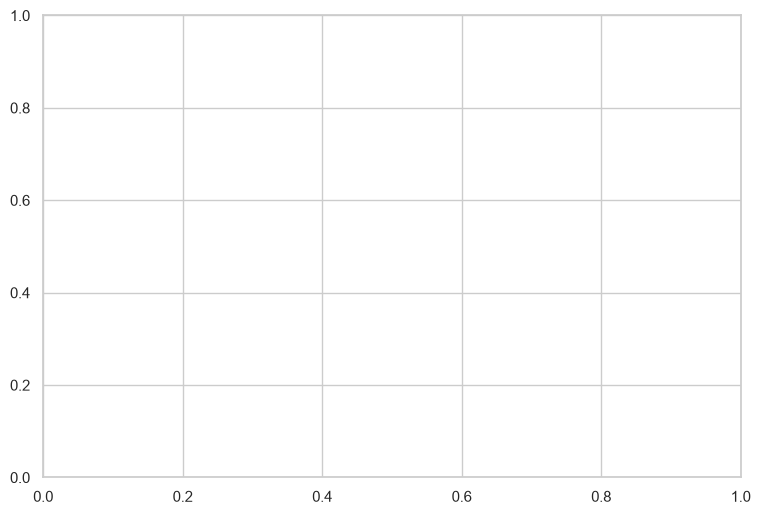

In [33]:
fig, ax = plt.subplots(
    figsize=(9, 6),
)

sns.barplot(
    data=selected_size_summary,
    x="cluster",
    y="respondents",
    ax=ax,
)

ax.set_title(
    f"Selected Solution: Cluster Sizes\n{SELECTED_MODEL_KEY}",
    weight="bold",
)

ax.set_xlabel("Cluster")

ax.set_ylabel("Number of respondents")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "selected_cluster_sizes.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

In [34]:
small_cluster_threshold = max(
    10,
    int(np.ceil(0.01 * EXPECTED_COHORT_SIZE)),
)

selected_size_summary["below_1_percent"] = (
    selected_size_summary["respondents"]
    < small_cluster_threshold
)

print(
    "Small-cluster review threshold:",
    small_cluster_threshold,
)

print(
    "Clusters below threshold:",
    int(
        selected_size_summary["below_1_percent"].sum()
    ),
)

display(
    selected_size_summary
)

NameError: name 'selected_size_summary' is not defined

### Cluster-size interpretation

The 1% threshold is a review flag, not an automatic rejection criterion.

A small cluster may represent a meaningful and distinctive workplace-climate pattern. However, it may also reflect:

- An unstable segmentation.
- A narrow response combination.
- A small group of unusual observations.
- Over-fragmentation.

The cluster should therefore be assessed using its response profile, model diagnostics and robustness evidence.

In [35]:
evaluation_data = cohort.copy()

evaluation_data["model_row_index"] = (
    row_mapping["model_row_index"].to_numpy()
)

evaluation_data["cluster"] = selected_labels

evaluation_data["is_noise"] = (
    evaluation_data["cluster"] == -1
)

assert len(evaluation_data) == EXPECTED_COHORT_SIZE

assert evaluation_data["model_row_index"].is_unique

assert evaluation_data[PRIMARY_FEATURES].notna().all().all()


assigned_data = evaluation_data.loc[
    evaluation_data["cluster"] != -1
].copy()


print("Total cohort:", len(evaluation_data))
print("Assigned respondents:", len(assigned_data))
print("Noise respondents:", len(evaluation_data) - len(assigned_data))

NameError: name 'selected_labels' is not defined

## 7. Interpret the selected clusters

The most important evaluation is whether the clusters represent meaningfully different workplace-climate patterns.

The analysis examines the original categorical responses rather than relying solely on numerical cluster identifiers.

For every feature, the notebook calculates:

- Response category.
- Number of respondents in each cluster selecting that category.
- Percentage within the cluster.
- Overall percentage among assigned respondents.

The percentages are calculated within each cluster, not across the entire dataset.

This makes it possible to identify the response patterns that characterise each group.

In [36]:
feature_profile_records = []

for cluster_id in sorted(
    assigned_data["cluster"].unique()
):

    cluster_data = assigned_data.loc[
        assigned_data["cluster"] == cluster_id
    ]

    cluster_size = len(cluster_data)

    for feature in PRIMARY_FEATURES:

        proportions = (
            cluster_data[feature]
            .value_counts(
                normalize=True,
                dropna=False,
            )
        )

        counts = (
            cluster_data[feature]
            .value_counts(
                dropna=False,
            )
        )

        for response in proportions.index:

            feature_profile_records.append({
                "cluster": int(cluster_id),
                "feature": feature,
                "response": str(response),
                "count": int(counts[response]),
                "percentage": float(
                    proportions[response]
                ),
                "cluster_size": cluster_size,
            })


feature_profiles = pd.DataFrame(
    feature_profile_records
)


feature_profiles = feature_profiles.merge(
    feature_metadata[
        ["feature", "domain", "measurement_type"]
    ],
    on="feature",
    how="left",
)


assert feature_profiles["domain"].notna().all()


display(
    feature_profiles.head(20)
)

NameError: name 'assigned_data' is not defined

In [37]:
dominant_responses = (
    feature_profiles
    .sort_values(
        ["cluster", "feature", "percentage"],
        ascending=[True, True, False],
    )
    .groupby(
        ["cluster", "feature"],
        as_index=False,
    )
    .first()
)


dominant_responses = dominant_responses.rename(
    columns={
        "response": "dominant_response",
        "count": "dominant_count",
        "percentage": "dominant_percentage",
    }
)


display(
    dominant_responses[
        [
            "cluster",
            "domain",
            "feature",
            "dominant_response",
            "dominant_count",
            "dominant_percentage",
        ]
    ]
)

NameError: name 'feature_profiles' is not defined

In [38]:
for domain, features in FEATURES_BY_DOMAIN.items():

    domain_data = feature_profiles.loc[
        feature_profiles["feature"].isin(features)
    ].copy()

    domain_data["feature"] = pd.Categorical(
        domain_data["feature"],
        categories=features,
        ordered=True,
    )

    pivot_data = domain_data.pivot_table(
        index=["cluster", "feature"],
        columns="response",
        values="percentage",
        fill_value=0,
        observed=False,
    )

    fig, ax = plt.subplots(
        figsize=(13, max(5, len(features) * 0.7)),
    )

    sns.heatmap(
        pivot_data,
        cmap="YlGnBu",
        annot=True,
        fmt=".0%",
        linewidths=0.4,
        ax=ax,
    )

    ax.set_title(
        f"Cluster Response Profiles — {domain.replace('_', ' ').title()}",
        weight="bold",
    )

    ax.set_xlabel("Response category")

    ax.set_ylabel("Cluster and feature")

    plt.xticks(rotation=35, ha="right")

    plt.tight_layout()

    plt.savefig(
        FIGURES_DIR / f"profile_{domain}.png",
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()

NameError: name 'feature_profiles' is not defined

### Domain-level interpretation

Individual features describe specific aspects of workplace climate. The domain-level summary helps identify broader patterns.

However, categorical responses are not automatically assigned a numerical score.

For example, the categories of a nominal variable do not have a meaningful numeric order. Averaging arbitrary category codes would therefore create a misleading result.

The analysis retains the original response categories and uses the feature-level profiles as its primary evidence.

The domain summary below counts the number of features for which each response is the dominant response within a cluster.

This is a descriptive indicator, not a validated domain score.

In [39]:
domain_dominance = (
    dominant_responses
    .groupby(
        ["cluster", "domain"],
        as_index=False,
    )
    .agg(
        features_with_dominant_response=(
            "feature",
            "count",
        ),
        mean_dominant_response_percentage=(
            "dominant_percentage",
            "mean",
        ),
    )
)


display(
    domain_dominance.style.format({
        "mean_dominant_response_percentage": "{:.2%}",
    })
)

NameError: name 'dominant_responses' is not defined

## 8. Do the features distinguish the clusters?

This section evaluates whether the distribution of each primary feature differs across the selected clusters.

For categorical features, a chi-square test of independence is used.

The test evaluates whether the distribution of responses is independent of cluster membership.

The analysis also calculates Cramér's V to quantify the strength of association.

The chi-square p-values are adjusted using the Benjamini–Hochberg procedure to control the false discovery rate across the 15 primary features.

### Important interpretation

A statistically significant association does not establish that the clustering is valid.

The clustering was constructed using these same features, so some association is expected.

This analysis is used to identify which features contribute most strongly to the observed cluster profiles, not as an independent validation of the clustering.

In [40]:
def cramers_v_bias_corrected(
    contingency_table,
):
    observed = np.asarray(
        contingency_table,
        dtype=float,
    )

    n = observed.sum()

    if n <= 1:
        return np.nan

    rows, columns = observed.shape

    if min(rows, columns) < 2:
        return np.nan

    chi2, _, _, _ = chi2_contingency(
        observed,
        correction=False,
    )

    phi2 = chi2 / n

    phi2_corrected = max(
        0,
        phi2 - (
            (columns - 1) * (rows - 1)
        ) / (n - 1),
    )

    rows_corrected = (
        rows - ((rows - 1) ** 2) / (n - 1)
    )

    columns_corrected = (
        columns - ((columns - 1) ** 2) / (n - 1)
    )

    denominator = min(
        rows_corrected - 1,
        columns_corrected - 1,
    )

    if denominator <= 0:
        return np.nan

    return np.sqrt(
        phi2_corrected / denominator
    )


primary_association_results = []

for feature in PRIMARY_FEATURES:

    contingency = pd.crosstab(
        assigned_data["cluster"],
        assigned_data[feature],
    )

    if (
        contingency.shape[0] < 2
        or contingency.shape[1] < 2
    ):
        continue

    chi2, p_value, degrees_freedom, expected = (
        chi2_contingency(
            contingency,
            correction=False,
        )
    )

    primary_association_results.append({
        "feature": feature,
        "domain": (
            feature_metadata
            .set_index("feature")
            .loc[feature, "domain"]
        ),
        "chi2": chi2,
        "degrees_freedom": degrees_freedom,
        "p_value": p_value,
        "cramers_v": cramers_v_bias_corrected(
            contingency
        ),
        "minimum_expected_frequency": expected.min(),
        "cells_expected_below_5": int(
            np.sum(expected < 5)
        ),
    })


primary_association = pd.DataFrame(
    primary_association_results
)


if not primary_association.empty:

    primary_association["p_adjusted"] = (
        multipletests(
            primary_association["p_value"],
            method="fdr_bh",
        )[1]
    )

    primary_association["significant_fdr_05"] = (
        primary_association["p_adjusted"] < 0.05
    )

    primary_association = (
        primary_association
        .sort_values(
            "cramers_v",
            ascending=False,
        )
        .reset_index(drop=True)
    )


display(
    primary_association.style.format({
        "p_value": "{:.4g}",
        "p_adjusted": "{:.4g}",
        "cramers_v": "{:.3f}",
    })
)

NameError: name 'assigned_data' is not defined

NameError: name 'primary_association' is not defined

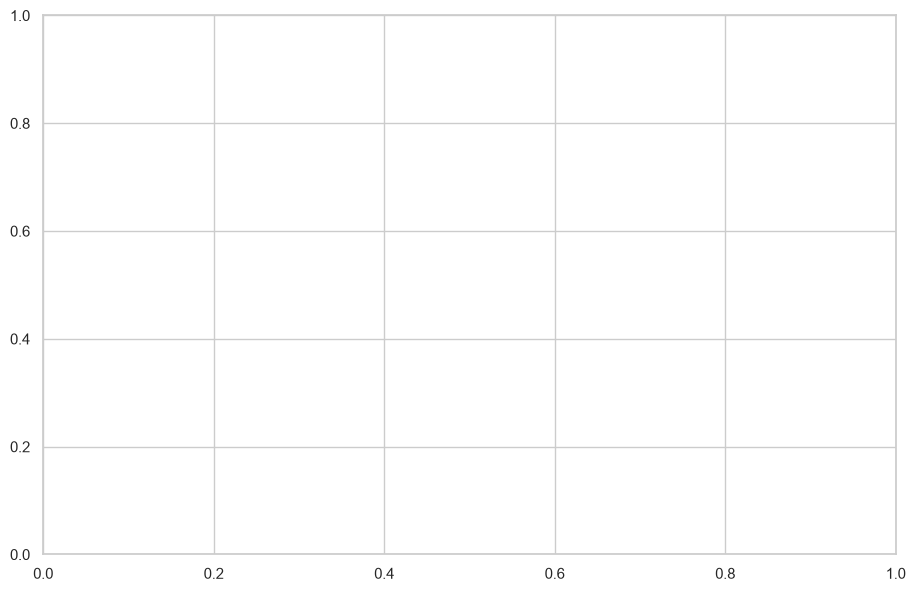

In [41]:
fig, ax = plt.subplots(
    figsize=(11, 7),
)

sns.barplot(
    data=primary_association.sort_values(
        "cramers_v",
        ascending=True,
    ),
    x="cramers_v",
    y="feature",
    hue="domain",
    dodge=False,
    ax=ax,
)

ax.set_title(
    "Association Strength Between Primary Features and Clusters",
    weight="bold",
)

ax.set_xlabel("Bias-corrected Cramér's V")

ax.set_ylabel("Feature")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "primary_feature_association_strength.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## 9. Supplementary external associations

The primary clustering deliberately excludes demographic and
contextual variables.

This section examines whether the resulting clusters are associated
with selected contextual variables that were not used to construct
the clustering.

The analysis is supplementary.

It can help describe the composition of clusters and identify
potential research questions. It cannot establish that demographic
characteristics cause workplace-climate differences.

The analysis is restricted to variables actually present in the
prepared cohort.

No missing contextual values are imputed.

Categorical variables are evaluated using chi-square tests and
bias-corrected Cramér's V.

Age, if available as a numeric variable, is evaluated using
Kruskal–Wallis rather than assuming normally distributed values.

In [42]:
CONTEXTUAL_CATEGORICAL_CANDIDATES = [
    "gender",
    "gender_profile",
    "country",
    "state",
    "company_size",
    "work_remote",
    "tech_company",
    "tech_role",
    "self_employed",
]

CONTEXTUAL_NUMERIC_CANDIDATES = [
    "age",
]


contextual_categorical_features = [
    column
    for column in CONTEXTUAL_CATEGORICAL_CANDIDATES
    if column in assigned_data.columns
]

contextual_numeric_features = [
    column
    for column in CONTEXTUAL_NUMERIC_CANDIDATES
    if column in assigned_data.columns
]


print(
    "Available categorical contextual variables:",
    contextual_categorical_features,
)

print(
    "Available numeric contextual variables:",
    contextual_numeric_features,
)

NameError: name 'assigned_data' is not defined

In [43]:
contextual_association_results = []

for feature in contextual_categorical_features:

    analysis_data = assigned_data[
        ["cluster", feature]
    ].dropna().copy()

    if analysis_data[feature].nunique() < 2:
        continue

    contingency = pd.crosstab(
        analysis_data["cluster"],
        analysis_data[feature],
    )

    if (
        contingency.shape[0] < 2
        or contingency.shape[1] < 2
    ):
        continue

    chi2, p_value, degrees_freedom, expected = (
        chi2_contingency(
            contingency,
            correction=False,
        )
    )

    contextual_association_results.append({
        "feature": feature,
        "test": "Chi-square",
        "sample_size": len(analysis_data),
        "chi2": chi2,
        "degrees_freedom": degrees_freedom,
        "p_value": p_value,
        "cramers_v": cramers_v_bias_corrected(
            contingency
        ),
        "minimum_expected_frequency": expected.min(),
        "cells_expected_below_5": int(
            np.sum(expected < 5)
        ),
    })


contextual_association = pd.DataFrame(
    contextual_association_results
)


if not contextual_association.empty:

    contextual_association["p_adjusted"] = (
        multipletests(
            contextual_association["p_value"],
            method="fdr_bh",
        )[1]
    )

    contextual_association = (
        contextual_association
        .sort_values(
            "cramers_v",
            ascending=False,
        )
        .reset_index(drop=True)
    )


display(
    contextual_association
)

NameError: name 'contextual_categorical_features' is not defined

In [44]:
numeric_association_results = []

for feature in contextual_numeric_features:

    analysis_data = assigned_data[
        ["cluster", feature]
    ].dropna().copy()

    if analysis_data["cluster"].nunique() < 2:
        continue

    groups = [
        group[feature].to_numpy()
        for _, group in analysis_data.groupby("cluster")
        if len(group) > 0
    ]

    if len(groups) < 2:
        continue

    statistic, p_value = kruskal(
        *groups
    )

    n = len(analysis_data)

    k = len(groups)

    eta_squared = max(
        0,
        (statistic - k + 1) / (n - k),
    ) if n > k else np.nan

    numeric_association_results.append({
        "feature": feature,
        "test": "Kruskal-Wallis",
        "sample_size": n,
        "statistic": statistic,
        "p_value": p_value,
        "eta_squared_approx": eta_squared,
    })


numeric_contextual_association = pd.DataFrame(
    numeric_association_results
)


if not numeric_contextual_association.empty:

    numeric_contextual_association["p_adjusted"] = (
        multipletests(
            numeric_contextual_association["p_value"],
            method="fdr_bh",
        )[1]
    )


display(
    numeric_contextual_association
)

NameError: name 'contextual_numeric_features' is not defined

In [45]:
contextual_profile_tables = {}

for feature in contextual_categorical_features:

    table = pd.crosstab(
        assigned_data["cluster"],
        assigned_data[feature],
        normalize="index",
    )

    contextual_profile_tables[feature] = table

    print(f"\n{feature}")

    display(
        table.style.format("{:.1%}")
    )

NameError: name 'contextual_categorical_features' is not defined

### Interpretation safeguards

Supplementary associations should be interpreted cautiously.

In particular:

- A cluster may contain a larger proportion of a demographic group
  without that group being responsible for the cluster's workplace
  climate.
- Small demographic categories may produce sparse contingency tables.
- Country and company-size categories may be highly heterogeneous.
- Gender categories should not be collapsed merely to obtain
  statistically significant results.
- Statistical significance does not establish practical importance.
- These results are exploratory and should be used to guide further
  research rather than employment decisions.

Cluster membership must not be used to diagnose an individual,
predict an individual's mental-health condition or make decisions
about hiring, promotion or employment.

## 10. Review model-specific diagnostics

This section reviews the diagnostics already calculated in
Notebook 03.

The objective is to ensure that the selected solution is consistent
with the evidence generated by its modelling method.

The diagnostics are not treated as interchangeable.

### K-Modes

Review:
- Categorical mismatch cost.
- Repeated-run consistency.
- Cluster-size distribution.

### MCA + K-Means

Review:
- MCA retained dimensions and inertia.
- Silhouette in MCA coordinates.
- Davies–Bouldin index.
- Calinski–Harabasz index.

### Agglomerative hierarchical clustering

Review:
- Gower silhouette.
- Cophenetic correlation.
- Cluster-size distribution.

Cophenetic correlation evaluates dendrogram fidelity, not the
quality of the final cluster partition.

### HDBSCAN

Review:
- DBCV, where validly calculated.
- Cluster persistence.
- Noise share.
- Assigned coverage.
- Membership strengths, where exported.

A missing or unsupported diagnostic must be reported as unavailable,
not silently interpreted as zero.

In [46]:
selected_metric_row = candidate_metrics.loc[
    candidate_metrics["model_key"] == SELECTED_MODEL_KEY
]

if selected_metric_row.empty:

    print(
        "No model-specific metrics were found for the selected model."
    )

else:

    display(
        selected_metric_row.T.rename(
            columns={
                selected_metric_row.index[0]: "Selected model"
            }
        )
    )

KeyError: 'model_key'

## 11. Stability and robustness evidence

A useful clustering solution should not depend excessively on
arbitrary initialisation or a narrow set of observations.

Notebook 03 contains the model-specific stability diagnostics
available for the candidate solutions.

The evaluation should distinguish:

- Repeated-initialisation stability.
- Resampling stability.
- Cluster persistence.
- Membership strength.

These measure different aspects of robustness.

For example, repeated K-Modes initialisations examine whether
different initial centroid choices produce similar solutions.

HDBSCAN persistence examines the stability of density-based
clusters across density levels.

Neither should be described as equivalent to a formal
subsampling-stability analysis.

If a formal resampling analysis was not performed in Notebook 03,
the final report must state that limitation rather than claiming
that the selected solution has passed a resampling test.

In [47]:
stability_columns = [
    column
    for column in candidate_metrics.columns
    if any(
        term in column.lower()
        for term in [
            "stability",
            "ari",
            "persistence",
            "membership",
            "cophenetic",
            "dbcv",
            "silhouette",
            "davies",
            "calinski",
            "cost",
        ]
    )
]

if stability_columns:

    display(
        candidate_metrics[
            ["model_key"] + stability_columns
        ]
    )

else:

    print(
        "No recognised model-specific diagnostic columns "
        "were found. Inspect the Notebook 03 metrics export."
    )

KeyError: "['model_key'] not in index"

In [48]:
selected_common_silhouette = (
    common_silhouette_summary
    .loc[
        common_silhouette_summary["model_key"]
        == SELECTED_MODEL_KEY,
        "gower_silhouette",
    ]
    .iloc[0]
)

selected_candidate_size = (
    candidate_size_summary
    .loc[
        candidate_size_summary["model_key"]
        == SELECTED_MODEL_KEY
    ]
    .iloc[0]
)


evaluation_summary = {
    "project": (
        "OSMI 2016 Mental Health in Technology-related Jobs"
    ),

    "notebook": "04_model_evaluation",

    "selected_model_key": SELECTED_MODEL_KEY,

    "cohort_size": EXPECTED_COHORT_SIZE,

    "primary_feature_count": EXPECTED_FEATURE_COUNT,

    "feature_domains": list(
        FEATURES_BY_DOMAIN.keys()
    ),

    "assigned_cluster_count": int(
        selected_cluster_count
    ),

    "assigned_respondents": int(
        selected_candidate_size["assigned_respondents"]
    ),

    "noise_count": int(
        selected_noise_count
    ),

    "noise_share": float(
        selected_noise_share
    ),

    "coverage": float(
        selected_coverage
    ),

    "common_gower_silhouette": (
        None
        if pd.isna(selected_common_silhouette)
        else float(selected_common_silhouette)
    ),

    "smallest_cluster_size": int(
        selected_candidate_size["smallest_cluster"]
    ),

    "largest_cluster_size": int(
        selected_candidate_size["largest_cluster"]
    ),

    "candidate_solution_count": len(
        candidate_model_keys
    ),

    "evaluation_scope": (
        "Exploratory workplace-climate segmentation"
    ),

    "causal_inference": False,

    "individual_diagnosis": False,
}


with open(
    EVALUATION_DIR / "osmi_2016_evaluation_summary.json",
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        evaluation_summary,
        file,
        indent=4,
        ensure_ascii=False,
    )


display(
    pd.DataFrame(
        evaluation_summary.items(),
        columns=["Evaluation measure", "Value"],
    )
)

IndexError: single positional indexer is out-of-bounds

## 12. Develop cluster descriptions

Cluster numbers are arbitrary identifiers.

A cluster labelled 0 is not inherently better, worse or more
important than a cluster labelled 1.

The cluster descriptions should be derived from the observed
response profiles.

Descriptions must:

- Reflect the dominant response patterns.
- Refer to the relevant workplace-climate domains.
- Avoid psychological or clinical labels.
- Avoid implying that the clusters represent employee diagnoses.
- Avoid unsupported claims about why a pattern exists.

The descriptions below provide a structured starting point.
They should be reviewed against the detailed response tables
before being included in the final portfolio report.

In [49]:
cluster_descriptions = []

for cluster_id in sorted(
    assigned_data["cluster"].unique()
):

    cluster_dominant = dominant_responses.loc[
        dominant_responses["cluster"] == cluster_id
    ].copy()

    cluster_dominant = cluster_dominant.sort_values(
        "dominant_percentage",
        ascending=False,
    )

    strongest_patterns = cluster_dominant.head(5)

    description_lines = []

    for _, row in strongest_patterns.iterrows():

        description_lines.append(
            f"{row['feature']}: "
            f"{row['dominant_response']} "
            f"({row['dominant_percentage']:.1%})"
        )


    cluster_descriptions.append({
        "cluster": int(cluster_id),
        "cluster_size": int(
            (assigned_data["cluster"] == cluster_id).sum()
        ),
        "cluster_percentage": float(
            (assigned_data["cluster"] == cluster_id).mean()
        ),
        "strongest_response_patterns": " | ".join(
            description_lines
        ),
    })


cluster_descriptions = pd.DataFrame(
    cluster_descriptions
)


display(
    cluster_descriptions
)

NameError: name 'assigned_data' is not defined

### Manual interpretation and naming

The numerical output above should be used to assign a descriptive
name to each cluster.

Names should describe workplace conditions, not people.

For example, a cluster may be characterised by:

- Strong organisational support.
- Mixed organisational support and psychological safety.
- Low perceived disclosure safety.
- Perceived career-related disclosure concerns.

These are examples of descriptive naming conventions, not
pre-assigned findings.

The actual cluster names must reflect the observed response
profiles in this dataset.

In [50]:
# Complete this dictionary after reviewing the response profiles.
#
# Use the actual cluster identifiers.
# Do not assign names based on assumptions.

CLUSTER_NAMES = {
    # Example structure:
    # 0: "Descriptive workplace-climate profile",
    # 1: "Descriptive workplace-climate profile",
}


if CLUSTER_NAMES:

    assert set(CLUSTER_NAMES.keys()).issubset(
        set(selected_cluster_labels)
    )

    cluster_descriptions["cluster_name"] = (
        cluster_descriptions["cluster"]
        .map(CLUSTER_NAMES)
    )

else:

    cluster_descriptions["cluster_name"] = (
        cluster_descriptions["cluster"]
        .map(lambda value: f"Cluster {value}")
    )


display(
    cluster_descriptions
)

TypeError: list indices must be integers or slices, not str

## 13. Translate the findings into organisational priorities

The purpose of the project is to understand workplace mental-health
climate patterns that may inform organisational action.

The recommendations must be based on observed findings rather
than generic mental-health advice.

The analysis distinguishes three levels:

### Organisation-wide priorities

Issues that appear across multiple clusters and may justify
organisation-wide attention.

### Cluster-specific priorities

Issues that are particularly prominent in one cluster.

### Further investigation

Patterns that require qualitative research or additional data
before a specific intervention can be recommended.

The recommendations should focus on workplace systems, policies,
leadership practices and psychological safety.

They should not treat employees as problems to be managed.

In [51]:
# Calculate the overall response distribution for each feature.

overall_feature_profiles = []

for feature in PRIMARY_FEATURES:

    proportions = (
        assigned_data[feature]
        .value_counts(
            normalize=True,
            dropna=False,
        )
    )

    for response, percentage in proportions.items():

        overall_feature_profiles.append({
            "feature": feature,
            "response": str(response),
            "overall_percentage": float(percentage),
        })


overall_feature_profiles = pd.DataFrame(
    overall_feature_profiles
)


overall_feature_profiles = overall_feature_profiles.merge(
    feature_metadata[
        ["feature", "domain"]
    ],
    on="feature",
    how="left",
)


display(
    overall_feature_profiles.sort_values(
        ["domain", "feature", "overall_percentage"],
        ascending=[True, True, False],
    )
)

NameError: name 'assigned_data' is not defined

In [52]:
cluster_vs_overall_records = []

for feature in PRIMARY_FEATURES:

    overall_distribution = (
        assigned_data[feature]
        .value_counts(normalize=True)
    )

    for cluster_id in selected_cluster_labels:

        cluster_data = assigned_data.loc[
            assigned_data["cluster"] == cluster_id
        ]

        cluster_distribution = (
            cluster_data[feature]
            .value_counts(normalize=True)
        )

        for response, cluster_percentage in (
            cluster_distribution.items()
        ):

            overall_percentage = (
                overall_distribution.get(
                    response,
                    0,
                )
            )

            cluster_vs_overall_records.append({
                "cluster": int(cluster_id),
                "feature": feature,
                "response": str(response),
                "cluster_percentage": float(
                    cluster_percentage
                ),
                "overall_percentage": float(
                    overall_percentage
                ),
                "percentage_point_difference": float(
                    cluster_percentage - overall_percentage
                ),
            })


cluster_vs_overall = pd.DataFrame(
    cluster_vs_overall_records
)


cluster_vs_overall = cluster_vs_overall.merge(
    feature_metadata[
        ["feature", "domain"]
    ],
    on="feature",
    how="left",
)


display(
    cluster_vs_overall.sort_values(
        "percentage_point_difference",
        key=lambda values: values.abs(),
        ascending=False,
    ).head(30)
)

NameError: name 'assigned_data' is not defined

### Recommendation evidence

The comparison with the overall cohort helps identify response
patterns that are unusually prominent within a cluster.

A percentage-point difference is descriptive.

It is not a causal effect and should not be interpreted as proof
that membership in a cluster causes a response.

The strongest deviations should be checked against:

- Cluster size.
- The number of respondents represented.
- The full response distribution.
- The consistency of the pattern across related features.
- The model's stability evidence.

In [53]:
recommendation_evidence = (
    cluster_vs_overall
    .assign(
        absolute_difference=lambda data:
            data["percentage_point_difference"].abs()
    )
    .sort_values(
        [
            "cluster",
            "absolute_difference",
        ],
        ascending=[
            True,
            False,
        ],
    )
    .groupby(
        "cluster",
        as_index=False,
    )
    .head(10)
    .reset_index(drop=True)
)


display(
    recommendation_evidence[
        [
            "cluster",
            "domain",
            "feature",
            "response",
            "cluster_percentage",
            "overall_percentage",
            "percentage_point_difference",
        ]
    ].style.format({
        "cluster_percentage": "{:.1%}",
        "overall_percentage": "{:.1%}",
        "percentage_point_difference": "{:+.1%}",
    })
)

NameError: name 'cluster_vs_overall' is not defined

## 14. Organisational recommendations

Recommendations should be written only after reviewing the
cluster response profiles and supplementary analysis.

The following structure should be used.

### Recommendation 1 — Strengthen organisational support

Evidence to consider:
- Availability and awareness of mental-health benefits.
- Access to resources.
- Formal organisational discussion.
- Anonymity and confidentiality protections.
- Medical leave arrangements.

Potential organisational action:
- Review whether existing support is accessible and understood.
- Evaluate whether confidentiality protections are clearly
  communicated.
- Assess whether policies are consistently implemented.

### Recommendation 2 — Improve psychological safety

Evidence to consider:
- Perceived consequences of disclosure.
- Comfort discussing mental health with colleagues.
- Comfort discussing mental health with supervisors.
- Observed negative consequences.

Potential organisational action:
- Train managers in supportive, non-punitive conversations.
- Establish clear reporting and escalation procedures.
- Review how managers respond to requests for support.
- Evaluate whether employees trust existing confidentiality
  arrangements.

### Recommendation 3 — Reduce disclosure-related career concerns

Evidence to consider:
- Perceived career consequences of disclosure.
- Willingness to disclose during interviews.
- Anticipated negative perceptions from colleagues.

Potential organisational action:
- Review recruitment and interview practices.
- Communicate that disclosure is not a condition of employment.
- Ensure mental-health support is separated from performance
  assessment wherever appropriate.
- Review policies for possible discriminatory effects.

### Recommendation 4 — Investigate differences between clusters

Evidence to consider:
- Distinctive response patterns.
- Cluster size and coverage.
- Supplementary contextual associations.
- Areas of uncertainty or weak statistical support.

Potential organisational action:
- Conduct confidential employee listening sessions.
- Use voluntary, anonymous qualitative research.
- Examine whether policy implementation differs between teams
  or organisational settings.

### Recommendation 5 — Monitor workplace climate over time

Evidence to consider:
- The exploratory nature of the 2016 survey.
- The absence of longitudinal evidence.
- The possibility that workplace conditions have changed.

Potential organisational action:
- Repeat a carefully designed employee climate survey.
- Monitor policy awareness and perceived psychological safety.
- Track organisational interventions using aggregated,
  privacy-preserving measures.

## 15. Final model assessment

The selected model should be assessed against five dimensions.

### 1. Separation

Does the solution produce meaningful separation according to
the appropriate distance or representation?

### 2. Robustness

Are there sufficient stability diagnostics to support confidence
that the solution is not an artefact of initialisation or a narrow
set of observations?

### 3. Cluster adequacy

Are the clusters large enough to support meaningful interpretation?
Does the model leave an acceptable proportion of respondents
unassigned, where applicable?

### 4. Interpretability

Do the response profiles describe coherent and distinguishable
workplace-climate patterns?

### 5. Practical usefulness

Can the findings inform organisational questions or improvements
without overstating what the data can establish?

A model may perform well on one dimension and less well on another.
The final decision must consider the combined evidence.

In [54]:
selected_model_assessment = {
    "selected_model": SELECTED_MODEL_KEY,

    "cluster_count": selected_cluster_count,

    "coverage": selected_coverage,

    "noise_share": selected_noise_share,

    "common_gower_silhouette": (
        None
        if pd.isna(selected_common_silhouette)
        else float(selected_common_silhouette)
    ),

    "smallest_cluster_size": int(
        selected_candidate_size["smallest_cluster"]
    ),

    "largest_cluster_size": int(
        selected_candidate_size["largest_cluster"]
    ),

    "cluster_profiles_available": (
        not feature_profiles.empty
    ),

    "primary_associations_available": (
        not primary_association.empty
    ),

    "contextual_associations_available": (
        not contextual_association.empty
    ),

    "model_specific_metrics_available": (
        not selected_metric_row.empty
    ),
}


display(
    pd.DataFrame(
        selected_model_assessment.items(),
        columns=[
            "Assessment dimension",
            "Result",
        ],
    )
)

NameError: name 'selected_cluster_count' is not defined

### Final recommendation decision

The final recommendation is a documented analytical judgement.

It is not automatically generated from a numerical threshold.

The analyst should select one of the following conclusions:

1. **Recommend for exploratory use**

   The solution has adequate separation, interpretable profiles,
   acceptable cluster sizes and sufficient supporting diagnostics
   for exploratory organisational analysis.

2. **Recommend with reservations**

   The solution provides useful profiles, but material limitations
   remain. These may include limited stability evidence, small
   clusters, substantial noise or weak separation.

3. **Do not recommend**

   The solution does not provide sufficiently coherent,
   interpretable or defensible clusters for the intended purpose.

The conclusion must be supported by the evidence presented
in this notebook.

In [55]:
FINAL_DECISION = None

FINAL_DECISION_OPTIONS = [
    "Recommend for exploratory use",
    "Recommend with reservations",
    "Do not recommend",
]

# Set the final decision after reviewing all evaluation results.
#
# Example:
# FINAL_DECISION = "Recommend with reservations"

if FINAL_DECISION not in FINAL_DECISION_OPTIONS:

    print(
        "Final decision not yet recorded. "
        "Review the evaluation results and set FINAL_DECISION."
    )

else:

    print("Final decision:", FINAL_DECISION)

Final decision not yet recorded. Review the evaluation results and set FINAL_DECISION.


In [56]:
FINAL_CONCLUSION = """
Write the final analytical conclusion here.

Address:
1. Which model was selected.
2. Why it was selected over the other candidates.
3. Whether the clusters are sufficiently distinct.
4. Whether cluster sizes and coverage are acceptable.
5. What the dominant workplace-climate profiles reveal.
6. Whether the supporting stability diagnostics are sufficient.
7. What the model can and cannot be used for.
8. Why the final recommendation is appropriate.
"""


if FINAL_DECISION is None:

    print(
        "Complete the final decision before exporting "
        "the final report."
    )

else:

    print(FINAL_CONCLUSION)

Complete the final decision before exporting the final report.


In [57]:
EXPORT_TABLES = {
    "candidate_evaluation": candidate_evaluation,

    "candidate_cluster_sizes": candidate_size_summary,

    "selected_cluster_sizes": selected_size_summary,

    "feature_profiles": feature_profiles,

    "dominant_responses": dominant_responses,

    "domain_dominance": domain_dominance,

    "primary_feature_associations": primary_association,

    "contextual_associations": contextual_association,

    "numeric_contextual_associations": (
        numeric_contextual_association
    ),

    "cluster_descriptions": cluster_descriptions,

    "overall_feature_profiles": overall_feature_profiles,

    "cluster_vs_overall": cluster_vs_overall,

    "recommendation_evidence": recommendation_evidence,
}


for name, table in EXPORT_TABLES.items():

    table.to_csv(
        TABLES_DIR / f"osmi_2016_{name}.csv",
        index=False,
    )


print("Evaluation tables exported.")

NameError: name 'selected_size_summary' is not defined

In [58]:
selected_labels_export = pd.DataFrame({
    "model_row_index": row_mapping["model_row_index"],
    "source_row_position": row_mapping["source_row_position"],
    "cluster": selected_labels,
})

if CLUSTER_NAMES:

    selected_labels_export["cluster_name"] = (
        selected_labels_export["cluster"]
        .map(CLUSTER_NAMES)
    )


selected_labels_export.to_csv(
    TABLES_DIR / "osmi_2016_final_cluster_assignments.csv",
    index=False,
)


print("Final cluster assignments exported.")

NameError: name 'selected_labels' is not defined

In [59]:
final_evaluation_metadata = {
    **evaluation_summary,

    "final_decision": FINAL_DECISION,

    "final_conclusion": FINAL_CONCLUSION,

    "cluster_names": {
        str(key): value
        for key, value in CLUSTER_NAMES.items()
    },

    "methodological_limitations": [
        "The analysis is cross-sectional.",
        "The survey represents responses collected in 2016.",
        "Clusters are exploratory workplace-climate segments.",
        "Cluster membership is not a mental-health diagnosis.",
        "Associations do not establish causation.",
        "Supplementary contextual variables were not used "
        "to construct the clusters.",
        "Model-specific metrics are not all directly comparable.",
    ],
}


with open(
    EVALUATION_DIR / "osmi_2016_final_evaluation.json",
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        final_evaluation_metadata,
        file,
        indent=4,
        ensure_ascii=False,
    )


print("Final evaluation metadata exported.")

NameError: name 'evaluation_summary' is not defined

In [60]:
exported_files = (
    list(TABLES_DIR.glob("*.csv"))
    + list(FIGURES_DIR.glob("*.png"))
    + list(EVALUATION_DIR.glob("*.json"))
)


export_audit = pd.DataFrame([
    {
        "filename": path.name,
        "directory": str(path.parent),
        "size_kb": round(
            path.stat().st_size / 1024,
            2,
        ),
        "exists": path.exists(),
    }
    for path in exported_files
])


display(
    export_audit
)


assert export_audit["exists"].all()

assert (
    export_audit["size_kb"] > 0
).all()


print(
    f"Verified {len(export_audit)} evaluation outputs."
)

,filename,directory,size_kb,exists
0,candidate_cluster_counts.png,c:\Users\User\Documents\Projects\osmi-mental-h...,349.25,True


Verified 1 evaluation outputs.


# Final conclusion

## Project outcome

This project applied four unsupervised clustering approaches
to a carefully defined cohort of 1,131 respondents from the
OSMI 2016 Mental Health in Technology-related Jobs survey.

The analysis focused on 15 workplace-climate features grouped
into three domains:

1. Employer support.
2. Psychological safety.
3. Disclosure and career climate.

The clustering models were:

- K-Modes.
- MCA followed by K-Means.
- Agglomerative hierarchical clustering using Gower dissimilarity.
- HDBSCAN using Gower dissimilarity.

The final evaluation considered cluster separation, model-specific
diagnostics, cluster-size distribution, coverage, response profiles,
supplementary contextual associations and practical interpretability.

## Interpretation

The resulting clusters should be understood as exploratory
workplace-climate profiles.

They represent patterns in respondents' reported perceptions
of organisational support, psychological safety and disclosure
climate.

They do not represent clinical categories, mental-health diagnoses
or fixed employee characteristics.

## Organisational relevance

The findings can help organisations identify areas where policies,
management practices, confidentiality arrangements and workplace
culture may warrant further investigation.

The clusters should be used to inform organisation-level learning
and improvement, not to classify or make decisions about individual
employees.

## Limitations

The data were collected in 2016 and are cross-sectional.
The findings therefore cannot establish current workplace
conditions or causal relationships.

The results should be validated with more recent employee data
and, where appropriate, qualitative research.

## Final recommendation

The final recommendation is recorded in the exported evaluation
metadata and should be supported by the evidence documented
throughout this notebook.